# Bloc 7 — Construire le narratif (Health, partie clinique)
Ce notebook rassemble ce que les blocs 1 à 6 ont trouvé sur `clinical_encounters`, `clinical_notes`, `clinical_observation`, `clinical_procedures` et `patient_administration`, sépare les **vrais indices** des **artefacts de génération**, reconstitue une **chronologie**, puis **teste les hypothèses** avec des méthodes du cours.

Chaque affirmation renvoie à une cellule : `eda.ipynb` (bloc 1), `clustering.ipynb` (bloc 2), `patterns_anomalies.ipynb` (bloc 3), `graphs_process.ipynb` (bloc 4), `spatio_temporal.ipynb` (bloc 5), `text_mining.ipynb` (bloc 6), ou une cellule de ce notebook (§ n).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 140)
chemin = 'cleaned/'
enc = pd.read_csv(chemin + 'clinical_encounters_cleaned.csv', parse_dates=['encounter_start', 'encounter_end', 'follow_up_date'])
obs = pd.read_csv(chemin + 'clinical_observation_cleaned.csv', parse_dates=['observation_time'])
proc = pd.read_csv(chemin + 'clinical_procedures_cleaned.csv', parse_dates=['scheduled_time', 'performed_time'])
notes = pd.read_csv(chemin + 'clinical_notes_cleaned.csv', parse_dates=['document_date'])
pat = pd.read_csv(chemin + 'patient_administration_cleaned.csv', parse_dates=['date_of_birth', 'registration_date'])

mrp = proc[proc.procedure_code == 'MRP-42']
elite = set(mrp[mrp.authorization_class == 'restricted_specialist'].patient_number)
recherche = set(mrp[mrp.authorization_class == 'research_restricted'].patient_number)
discordants = set(obs[obs.interpretation_code == 'discordant'].patient_number)
notes_redigees = ['CLN-510027', 'CLN-510025', 'CLN-510055', 'CLN-510064']
print(len(elite), 'patients MRP-42 specialist |', len(recherche), 'patients MRP-42 recherche |', len(discordants), 'patients discordants')

8 patients MRP-42 specialist | 20 patients MRP-42 recherche | 35 patients discordants


## 1. Tableau des indices
| # | Fichier | Observation | Méthode (où) | Hypothèse | Nature |
|---|---|---|---|---|---|
| 1 | `clinical_procedures` | 50 `MRP-42` (« Targeted metabolic resilience administration ») isolées, matériel unique, issues propres | CAH Hamming, K-Means (bloc 2 §4) ; Apriori lift 15,5 / 10,3 (bloc 3 §4.1) | Programme à part | **Indice** |
| 2 | `clinical_procedures` + `patient_administration` | 30 `restricted_specialist` pour **8 dirigeants** (chef de gouvernement, ministre, gouverneur, PDG...) ; 20 `research_restricted` pour 20 personnes ordinaires | Croisement (§ 2) | Traitement réservé à une élite + essai sur des sujets ordinaires | **Indice** |
| 3 | `clinical_procedures` | Les 30 `specialist` sont **toutes** faites par `LIC-VLN-MED-1002` | Centralités et Louvain sur le graphe restreint (bloc 4 §3-4) | Circuit fermé autour d'un praticien (Dr. Naima Orrel, `public_records`) | **Indice** |
| 4 | `clinical_procedures` | Une administration tous les **~742 jours** depuis 2014 ; volet recherche à partir de déc. 2019 | Intervalles entre événements (bloc 5 §6) | Protocole périodique, essai plus tardif | **Indice** |
| 5 | `clinical_encounters` | Cycle `executive_health_review` → `specialist_procedure` répété chez les 8 | DFG, variantes (bloc 4 §5) | Parcours dédié | **Indice** |
| 6 | `clinical_observation` | Âge biologique **≈ 12 ans** sous l'âge réel après `MRP-42` chez les 8 | Test avant / après (§ 4.1) | `MRP-42` ralentit le vieillissement mesuré | **Indice principal** |
| 7 | `clinical_observation` | 109 `discordant` : fréquence apicale ≈ +20 bpm au-dessus du pouls, chez 35 patients | Écart apical − pouls, LOF / IF (bloc 3 §3.3) ; nuage de points (bloc 1 §5) | Deux sources cardiaques | **Indice principal** |
| 8 | `clinical_observation` | Les 35 discordants ont aussi plus de balancement, de « second pic » thoracique et une reconnaissance caméra/thermique plus faible | Tests et clustering sur profils patients (§ 4.2) | Phénotype multivarié | **Indice** |
| 9 | `clinical_notes` | 4 notes rédigées : seconde source cardiaque (PAT-31065), capture d'image (PAT-31115), démarche + regard + rythme (PAT-31012), identité publique « Elias Voss » (PAT-31065) | TF-IDF, similarité, IQR, z modifié, CAH, concordancier (bloc 6 §6-8) | Le récit est écrit dans ces 4 notes | **Indice** |
| 10 | `clinical_notes` | *dual cardiac structures* **rejeté** (CLN-510126) ; *appearance control* = réglage caméra (CLN-510039) | Lecture du contexte (bloc 6 §8) | — | **Leurres** |
| 11 | `patient_administration` | 239/240 inscriptions au 1er du mois ; âges presque uniformes | Jour du mois (bloc 1 §2), histogramme (bloc 1 §3) | — | **Artefact** |
| 12 | `clinical_encounters` | 22 consultations le 2025-06-20 à 13 h 15 = dernières visites, suivi plafonné à cette date | Fenêtre glissante + z modifié (bloc 5 §5) | — | **Artefact** |
| 13 | `clinical_notes` | 8 notes datées avant leur consultation (jusqu'à −1 249 j) ; 42 phrases dupliquées ; 26 gabarits | Délais (bloc 3 §2), dédoublonnage (bloc 6 §2) | — | **Artefact** |
| 14 | `clinical_encounters`, `clinical_procedures` | Durées fixes (180 / 240 min), retards fixes (35 / 40 min), heures fixes (09 h 05 / 10 h 40), jeudi-vendredi | IQR, z modifié (bloc 3) ; bloc 5 §6 | Signature du protocole `MRP-42`, mise en forme par le générateur | Indice de **classe**, pas de cas |

## 2. Qui reçoit `MRP-42` ?

In [2]:
recap = (mrp.merge(pat[['patient_number', 'occupation_text', 'home_region', 'record_status', 'date_of_birth']])
            .groupby(['authorization_class', 'patient_number', 'occupation_text', 'home_region', 'record_status'])
            .agg(administrations=('procedure_record_id', 'size'), premiere=('performed_time', 'min'), derniere=('performed_time', 'max'),
                 praticiens=('performing_license_number', lambda s: ', '.join(sorted(s.unique())))).reset_index())
recap[recap.authorization_class == 'restricted_specialist']

,authorization_class,patient_number,occupation_text,home_region,record_status,administrations,premiere,derniere,praticiens
20,restricted_specialist,PAT-31044,senior minister of the avelora federation,avelora federation,active,4,2017-05-12 09:05:00,2024-08-23 09:05:00,LIC-VLN-MED-1002
21,restricted_specialist,PAT-31074,executive chair of nivren maritime logistics,nordhaven union,active,4,2017-11-03 09:05:00,2025-01-31 09:05:00,LIC-VLN-MED-1002
22,restricted_specialist,PAT-31099,retired political intermediary and former council president,avelora federation,deceased,3,2014-07-18 09:05:00,2018-08-10 09:05:00,LIC-VLN-MED-1002
23,restricted_specialist,PAT-31119,chief executive of solvane energy group,valenne republic,active,4,2018-01-26 09:05:00,2024-02-09 09:05:00,LIC-VLN-MED-1002
24,restricted_specialist,PAT-31142,chair of belen agro-industries,kintara republic,active,3,2019-03-14 09:05:00,2023-04-06 09:05:00,LIC-VLN-MED-1002
25,restricted_specialist,PAT-31174,regional governor in the tembara commonwealth,tembara commonwealth,active,4,2015-09-10 09:05:00,2021-10-14 09:05:00,LIC-VLN-MED-1002
26,restricted_specialist,PAT-31183,executive director of ardena capital union,valenne republic,active,3,2016-06-16 09:05:00,2020-07-02 09:05:00,LIC-VLN-MED-1002
27,restricted_specialist,PAT-31221,head of government of kintara republic,kintara republic,active,5,2016-02-18 09:05:00,2024-03-01 09:05:00,LIC-VLN-MED-1002


In [3]:
r = recap[recap.authorization_class == 'research_restricted']
print('Volet recherche :', len(r), 'patients, 1 administration chacun, entre', r.premiere.min().date(), 'et', r.derniere.max().date())
print('Professions :', r.occupation_text.value_counts().to_dict())
print('Praticiens :', mrp[mrp.authorization_class == 'research_restricted'].performing_license_number.value_counts().to_dict())

Volet recherche : 20 patients, 1 administration chacun, entre 2019-12-16 et 2024-04-08
Professions : {'research assistant': 5, 'transport worker': 3, 'retired professional': 3, 'small-business owner': 2, 'technician': 2, 'regional administrative director': 1, 'administrative employee': 1, 'council vice-president': 1, 'teacher': 1, 'agricultural worker': 1}
Praticiens : {'LIC-VLN-MED-1002': 6, 'LIC-VLN-MED-1006': 4, 'LIC-VLN-RES-1016': 3, 'LIC-VLN-MED-1004': 3, 'LIC-VLN-RES-1044': 2, 'LIC-VLN-MED-1003': 1, 'LIC-VLN-MED-1001': 1}


- Les 8 patients `specialist` sont des **dirigeants politiques et économiques de 5 pays** : chef de gouvernement de Kintara, ministre de l'Avelora, gouverneur du Tembara, présidents de Solvane Energy, Nivren Maritime Logistics, Ardena Capital Union, Belen Agro-industries, et une ancienne présidente de conseil (née en 1935, dossier `deceased`). Ils reçoivent 3 à 5 administrations chacun, **toutes** par `LIC-VLN-MED-1002`.
- Les 20 patients `research` ont des professions ordinaires (assistants de recherche, ouvriers des transports, retraités, techniciens...), reçoivent **une seule** administration, par 7 praticiens différents.
- Les anomalies multivariées du bloc 3 (PAT-31099, PAT-31174, PAT-31183, « dossiers anciens, professions dirigeantes ») sont **expliquées** : ce sont trois des 8 patients `specialist`. Leurs dossiers sont anciens parce que le programme commence en 2014.

## 3. Chronologie

In [4]:
evts = []
for p_, x in mrp[mrp.authorization_class == 'restricted_specialist'].groupby('patient_number').performed_time.min().sort_values().items():
    evts.append((x, f'1re administration MRP-42 specialist ({p_})'))
evts += [(mrp[mrp.authorization_class == 'research_restricted'].performed_time.min(), 'début du volet recherche MRP-42'),
         (pat.registration_date.min(), 'première inscription (PAT-31099)'),
         (pd.Timestamp('2017-01-01'), 'début des inscriptions en masse (2017-2021)')]
for _, n in notes[notes.document_id.isin(notes_redigees + ['CLN-510126', 'CLN-510039'])].iterrows():
    evts.append((n.document_date, f'note {n.document_id} ({n.patient_number}, {n.document_type}, {n.title})'))
evts += [(enc[enc.patient_number == 'PAT-31099'].encounter_start.max(), 'dernière consultation de PAT-31099 (dossier deceased)'),
         (mrp.performed_time.max(), 'dernière administration MRP-42'),
         (pd.Timestamp('2025-06-20'), 'artefact : 22 consultations plafonnées'),
         (enc.encounter_start.max(), 'dernière consultation du jeu (PAT-31065)')]
chrono = pd.DataFrame(evts, columns=['date', 'événement']).sort_values('date').reset_index(drop=True)
chrono['date'] = chrono.date.dt.date
chrono

,date,événement
0,2014-01-01,première inscription (PAT-31099)
1,2014-07-18,1re administration MRP-42 specialist (PAT-31099)
2,2015-09-10,1re administration MRP-42 specialist (PAT-31174)
3,2016-02-18,1re administration MRP-42 specialist (PAT-31221)
4,2016-06-16,1re administration MRP-42 specialist (PAT-31183)
5,2017-01-01,début des inscriptions en masse (2017-2021)
6,2017-05-12,1re administration MRP-42 specialist (PAT-31044)
7,2017-11-03,1re administration MRP-42 specialist (PAT-31074)
8,2018-01-26,1re administration MRP-42 specialist (PAT-31119)
9,2018-09-17,dernière consultation de PAT-31099 (dossier deceased)


**Lecture de la chronologie**
1. **2014-2019** : le traitement `MRP-42` commence pour une ancienne présidente de conseil (2014), puis s'étend à 7 autres dirigeants. Tous sont suivis par le même praticien, dans les deux cliniques Asterion.
2. **2017-2021** : la clinique inscrit la grande cohorte de patients ordinaires (bloc 5 §1).
3. **Fin 2019-2024** : un volet « recherche » administre `MRP-42` une seule fois à 20 patients ordinaires, avec un pic en 2023.
4. **2023-2025** : les notes rédigées décrivent un phénotype inhabituel (seconde source cardiaque, démarche, regard, capture d'image), puis relient PAT-31065 à une identité publique (janvier 2025).
5. Dates de notes à manier avec prudence : 8 notes sont antérieures à leur consultation (artefact n° 13).

## 4. Hypothèses et tests
### 4.1 H1 : `MRP-42` abaisse l'âge biologique mesuré
On définit, pour chaque mesure `bioage`, l'**écart** = âge biologique − âge réel au moment de la mesure. Si `MRP-42` agit, l'écart doit baisser **après** la première administration, chez les patients traités et pas chez les autres.

In [5]:
ba = obs[obs.observation_code == 'bioage'].merge(pat[['patient_number', 'date_of_birth']])
ba['age_reel'] = (ba.observation_time - ba.date_of_birth).dt.days / 365.25
ba['ecart'] = ba.numeric_value - ba.age_reel
premiere = mrp.groupby('patient_number').performed_time.min()
ba['apres'] = ba.observation_time > ba.patient_number.map(premiere)
ba['groupe'] = np.select([ba.patient_number.isin(elite), ba.patient_number.isin(recherche)], ['MRP-42 specialist', 'MRP-42 recherche'], 'autre')
ba['periode'] = np.where(ba.groupe == 'autre', '—', np.where(ba.apres, 'après', 'avant'))
display(ba.groupby(['groupe', 'periode']).ecart.agg(['count', 'mean', 'median']).round(1))

par_patient = ba.groupby(['groupe', 'patient_number', 'periode']).ecart.mean().reset_index()
autres = par_patient[par_patient.groupe == 'autre'].ecart
spec_apres = par_patient[(par_patient.groupe == 'MRP-42 specialist') & (par_patient.periode == 'après')].ecart
print(f'Mann-Whitney (moyenne par patient) specialist après vs autres : U = {stats.mannwhitneyu(spec_apres, autres).statistic:.0f}, '
      f'p = {stats.mannwhitneyu(spec_apres, autres).pvalue:.1e} ({len(spec_apres)} vs {len(autres)} patients)')

apparie = par_patient[par_patient.groupe == 'MRP-42 specialist'].pivot(index='patient_number', columns='periode', values='ecart').dropna()
print('Patients specialist mesurés avant ET après :', len(apparie), '| écart baisse chez', (apparie['après'] < apparie['avant']).sum(), 'sur', len(apparie))
print('Wilcoxon apparié :', stats.wilcoxon(apparie['après'], apparie['avant']))
pente = np.polyfit(ba[ba.groupe == 'autre'].age_reel, ba[ba.groupe == 'autre'].ecart, 1)[0]
print(f"Contrôle : chez les patients non traités, l'écart ne dépend pas de l'âge (pente = {pente:.3f} an par an)")

count  mean  median
groupe            periode                     
MRP-42 recherche  après       17  -2.4     1.0
                  avant       65  -0.8    -1.2
MRP-42 specialist après       30 -12.4   -12.2
                  avant        5  -4.6    -4.4
autre             —          817  -1.0    -1.2

Mann-Whitney (moyenne par patient) specialist après vs autres : U = 8, p = 1.1e-12 (8 vs 212 patients)
Patients specialist mesurés avant ET après : 5 | écart baisse chez 5 sur 5
Wilcoxon apparié : WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.0625))
Contrôle : chez les patients non traités, l'écart ne dépend pas de l'âge (pente = -0.004 an par an)


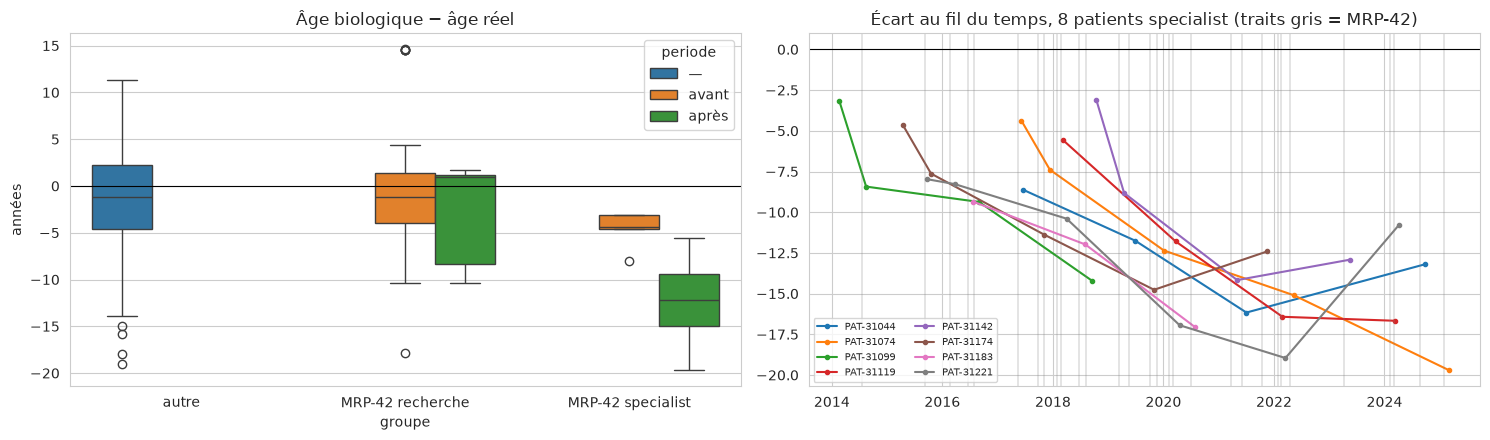

/tmp/ipykernel_4698/4248191269.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ba[ba.patient_number == 'PAT-31099'][['observation_time', 'age_reel', 'numeric_value', 'ecart']].round(1)


,observation_time,age_reel,numeric_value,ecart
83,2014-02-18 09:31:30,78.4,75.3,-3.1
84,2014-08-15 10:31:30,78.9,70.5,-8.4
85,2016-08-31 11:31:30,81.0,71.6,-9.4
86,2018-09-17 12:31:30,83.0,68.8,-14.2


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=ba, x='groupe', y='ecart', hue='periode', order=['autre', 'MRP-42 recherche', 'MRP-42 specialist'], ax=axes[0])
axes[0].axhline(0, color='k', lw=.8); axes[0].set_title('Âge biologique − âge réel'); axes[0].set_ylabel('années')
for p_ in sorted(elite):
    s = ba[ba.patient_number == p_].sort_values('observation_time')
    axes[1].plot(s.observation_time, s.ecart, 'o-', ms=3, label=p_)
    for d in mrp[mrp.patient_number == p_].performed_time:
        axes[1].axvline(d, color='grey', lw=.3)
axes[1].axhline(0, color='k', lw=.8); axes[1].set_title('Écart au fil du temps, 8 patients specialist (traits gris = MRP-42)')
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
ba[ba.patient_number == 'PAT-31099'][['observation_time', 'age_reel', 'numeric_value', 'ecart']].round(1)

**Résultat H1 : soutenue.**
- Chez les patients non traités, l'âge biologique suit l'âge réel (écart médian ≈ −1 an, sans dérive avec l'âge). Chez les 8 patients `specialist`, l'écart passe d'environ **−4,6 ans avant** à **−12,4 ans après** la première administration ; la différence avec les autres patients est très significative (Mann-Whitney).
- Les 5 patients mesurés avant **et** après baissent tous ; le Wilcoxon apparié donne p = 0,0625, soit **la plus petite valeur possible avec 5 paires** : le test ne peut pas faire mieux avec si peu de patients, le signal est cohérent mais l'effectif est faible.
- Exemple le plus parlant : **PAT-31099** (née en 1935) a un âge biologique qui **baisse** de 75 à 69 ans pendant que son âge réel passe de 78 à 83 ans.
- Le volet **recherche** ne montre **pas** d'effet (écart médian proche de 0 avant comme après). Mais la plupart de ces patients n'ont plus de mesure après leur unique administration, le test y a donc très peu de puissance.

**Explications alternatives**
- *Sélection* : des dirigeants ont accès à de meilleurs soins et sont peut-être en meilleure santé au départ. Mais l'écart **change après** la première administration chez les mêmes personnes : la sélection seule n'explique pas un changement intra-individuel.
- *Régression vers la moyenne* : improbable, l'écart s'éloigne de 0 au lieu d'y revenir.
- *Artefact de mesure* : `bioage` est une estimation calculée ; si l'algorithme utilisait le statut ou la procédure, l'écart serait mécanique. On ne peut pas l'exclure avec ces seules données.

### 4.2 H2 : les patients discordants forment un phénotype multivarié
Les notes rédigées décrivent des patients qui cumulent : seconde source cardiaque, démarche qui oscille avec un bon équilibre, mouvements oculaires en partie indépendants, mauvaise reconnaissance caméra et thermique. Si c'est un vrai phénotype, les 35 patients discordants (définis **uniquement** par l'écart apical / pouls) doivent aussi différer sur les **autres** mesures.

In [7]:
profil = obs.pivot_table(index='patient_number', columns='observation_code', values='numeric_value', aggfunc='mean')
profil['asym_regard'] = (profil.lefteye + profil.righteye).abs()   # les deux yeux ne dévient pas de façon symétrique
variables = ['latsway', 'balance', 'thorpeak', 'thorvib', 'cammatch', 'idcons', 'thermqual', 'asym_regard', 'gaitsym', 'mobility', 'cognitive', 'o2sat']
profil['discordant'] = profil.index.isin(discordants)
lignes = []
for v in variables:
    a_, b_ = profil.loc[profil.discordant, v], profil.loc[~profil.discordant, v]
    p_ = stats.mannwhitneyu(a_, b_).pvalue
    lignes.append({'variable': v, 'médiane discordants': a_.median(), 'médiane autres': b_.median(), 'p': p_,
                   'significatif (Bonferroni)': p_ < 0.05 / len(variables)})
pd.DataFrame(lignes).round(4)

,variable,médiane discordants,médiane autres,p,significatif (Bonferroni)
0,latsway,45.5600,28.7333,0.0001,True
1,balance,74.4750,78.3500,0.1246,False
2,thorpeak,53.4600,23.0500,0.0000,True
3,thorvib,38.3000,27.7000,0.0001,True
4,cammatch,87.2000,91.7000,0.0031,True
5,idcons,91.3000,93.5000,0.1071,False
6,thermqual,86.4000,90.5000,0.0086,False
7,asym_regard,3.2000,2.9000,0.9192,False
8,gaitsym,78.5000,81.9000,0.1821,False
9,mobility,79.6667,82.4500,0.3092,False


In [8]:
# Sans utiliser la fréquence apicale : un algorithme non supervisé retrouve-t-il les discordants ?
X = StandardScaler().fit_transform(profil[['latsway', 'thorpeak', 'thorvib', 'cammatch', 'thermqual', 'asym_regard']])
iso = IsolationForest(contamination=35 / 240, random_state=0).fit(X)
profil['iso_anomalie'] = iso.predict(X) == -1
km = KMeans(n_clusters=2, n_init=20, random_state=0).fit(X)
profil['kmeans'] = km.labels_
print('Isolation Forest (35 anomalies) :', (profil.iso_anomalie & profil.discordant).sum(), 'discordants retrouvés sur 35')
print('K-Means k=2 :', pd.crosstab(profil.discordant, profil.kmeans).to_dict(), '| ARI =', round(adjusted_rand_score(profil.discordant, profil.kmeans), 2))
print('Patients des notes rédigées :', {p_: ('discordant' if p_ in discordants else 'non') for p_ in ['PAT-31065', 'PAT-31115', 'PAT-31012']})

Isolation Forest (35 anomalies) : 19 discordants retrouvés sur 35
K-Means k=2 : {0: {False: 10, True: 19}, 1: {False: 195, True: 16}} | ARI = 0.46
Patients des notes rédigées : {'PAT-31065': 'discordant', 'PAT-31115': 'discordant', 'PAT-31012': 'discordant'}


**Résultat H2 : soutenue en partie.**
- Les patients discordants, définis seulement par leur rythme cardiaque, ont aussi un **balancement latéral** plus fort, des indices thoraciques (**second pic**, **vibration**) plus élevés et une **reconnaissance caméra** plus faible : 4 différences significatives après correction de Bonferroni (12 tests). La qualité thermique va dans le même sens (p ≈ 0,009, non significatif après correction).
- Les variables « témoins » (mobilité, cognition, saturation, symétrie de la marche) ne diffèrent pas : ce n'est pas un groupe de patients « en plus mauvaise santé ».
- En revanche, l'**équilibre** et l'**asymétrie du regard** (mesurée ici par la somme des déviations gauche et droite, une approximation grossière) ne diffèrent pas : ces deux éléments des notes ne sont pas confirmés par les mesures disponibles.
- Sans l'information cardiaque, un Isolation Forest retrouve **19 discordants sur 35**, et un K-Means à 2 groupes isole un cluster de 29 patients dont 19 discordants (ARI ≈ 0,46). Les trois patients des notes rédigées sont tous discordants.

**Explications alternatives** : un problème d'appareil expliquerait la discordance cardiaque, mais pas un balancement et une reconnaissance faciale dégradés chez les mêmes patients, sur des appareils et dans des sites différents (bloc 5 §2). Une maladie rare connue reste possible, ce que la note CLN-510064 discute elle-même.

### 4.3 H3 (abandonnée) : `MRP-42` provoque le phénotype discordant

In [9]:
tab = pd.crosstab(pd.Series([p_ in (elite | recherche) for p_ in pat.patient_number], name='MRP-42'),
                  pd.Series([p_ in discordants for p_ in pat.patient_number], name='discordant'))
print(tab)
print('Test exact de Fisher :', stats.fisher_exact(tab.values))
print('Discordants parmi les 8 specialist :', len(elite & discordants), '| parmi les 20 recherche :', sorted(recherche & discordants))

discordant  False  True 
MRP-42                  
False         180     32
True           25      3
Test exact de Fisher : SignificanceResult(statistic=np.float64(0.675), pvalue=np.float64(0.776162344060358))
Discordants parmi les 8 specialist : 0 | parmi les 20 recherche : ['PAT-31002', 'PAT-31077', 'PAT-31100']


**Résultat H3 : rejetée.** Aucun des 8 patients `specialist` n'est discordant, et 3 sujets de recherche seulement (proportion comparable au reste des patients, Fisher non significatif). Les deux phénomènes (programme `MRP-42` et phénotype discordant) sont **indépendants** dans les données cliniques : ce sont deux fils du récit, pas une cause et son effet. Il faudra voir avec les autres domaines s'ils se rejoignent ailleurs (par exemple via `LIC-VLN-MED-1002`, qui suit aussi PAT-31065 : bloc 4 §3).

### 4.4 H4 (à croiser) : PAT-31065 est Elias Voss

In [10]:
display(pat[pat.patient_number == 'PAT-31065'])
display(enc[enc.patient_number == 'PAT-31065'][['encounter_number', 'encounter_start', 'encounter_type', 'referral_source', 'attending_license_number', 'confidentiality_class']])
voss = pd.read_csv('../public_records/officer_filings_cleaned.csv')
voss[voss.full_name.str.contains('Voss', na=False)]

,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region,occupation_text,registration_date,primary_facility_license,record_status
6,PAT-31065,hallen,corin,1975-10-09,male,valenne republic,clinical specialist,2018-08-01,FAC-VLN-101,active


,encounter_number,encounter_start,encounter_type,referral_source,attending_license_number,confidentiality_class
33,ENC-000034,2018-09-06 09:15:00,cardiac_assessment,research programme,LIC-VLN-MED-1006,confidential
34,ENC-000035,2020-02-28 10:15:00,cardiac_assessment,executive health office,LIC-VLN-MED-1006,standard
35,ENC-000036,2021-07-18 11:15:00,cardiac_assessment,research programme,LIC-VLN-MED-1003,confidential
36,ENC-000037,2023-01-19 12:15:00,mobility_assessment,self,LIC-VLN-MED-1006,standard
37,ENC-000038,2024-06-12 13:15:00,specialist_follow_up,primary care,LIC-VLN-MED-1002,confidential
38,ENC-000039,2026-01-11 14:15:00,ocular_assessment,primary care,LIC-VLN-RES-1016,confidential


,filing_id,registration_number,officer_local_ref,full_name,birth_year_or_age_band,nationality_or_region,role_title,appointment_date,cessation_date,filing_date,service_address,filing_status
3,FLG-000004,REG-VLN-01001,OFR-20004,Dr. Elias Voss,1961,Valennan,Executive chair of Meridian BioLogistics,1996-01-01,NaN,1996-02-15,Meridian Valenne Headquarters,active


**Résultat H4 : non tranchée par la partie clinique.**
- La note CLN-510025 affirme que PAT-31065 se relie à **Elias Voss** par recoupement d'attributs publics, et que le lien résiste au retrait de chaque attribut.
- Mais le dossier administratif de PAT-31065 indique *Corin Hallen*, né en **1975**, « clinical specialist », alors que `officer_filings` donne Elias Voss né en **1961**, président exécutif de Meridian BioLogistics. Les données cliniques ne confirment donc pas la date de naissance ; soit l'identité clinique est un nom d'emprunt, soit le rapprochement est faux.
- `public_records` évoque aussi une continuité d'alias (*Adrian Vosmere*). La piste est à confronter avec le groupe `public_records` avant toute conclusion.

## 5. Pistes abandonnées
| Piste | Pourquoi abandonnée |
|---|---|
| Retards de 59 et 177 jours (PRC-000054, PRC-000071) | Deux cas isolés, patients sans autre particularité : erreur de saisie ou replanification (bloc 3 §4) |
| Effet de la région ou du site sur la discordance | χ² non significatif, discordance présente dans les 3 sites (bloc 5 §2-3) |
| Saisonnalité des consultations | ACF sans pic à 12 mois, composante saisonnière < résidu (bloc 5 §3-4) |
| Corrélation consultations / discordants | Tendance commune (cohorte), disparaît en taux (bloc 5 §2) |
| Topics LDA comme indices | Instables d'une graine à l'autre (bloc 6 §7) |
| Règles d'association sur `patient_administration` | Aucune règle (bloc 3 §5.1) |
| `MRP-42` → phénotype discordant | Rejetée (§ 4.3) |

## 6. Narratif proposé (partie clinique)
> Depuis 2014, un petit cercle de **8 dirigeants politiques et économiques** de cinq pays reçoit tous les deux ans, dans les cliniques de l'Asterion Clinical Institute et par un seul médecin (`LIC-VLN-MED-1002`, Dr. Naima Orrel), une procédure confidentielle, `MRP-42` (« metabolic resilience »). Après la première administration, leur âge biologique mesuré passe environ **12 ans sous leur âge réel**. À partir de fin 2019, la même procédure est administrée une seule fois à **20 personnes ordinaires** dans un cadre de « recherche », sans effet mesurable.
>
> En parallèle, **35 patients** présentent un phénotype inexpliqué : une seconde source de battements cardiaques (fréquence apicale ≈ 20 bpm au-dessus du pouls), un balancement latéral plus fort, des signaux thoraciques secondaires et des visages que les caméras reconnaissent moins bien. Les notes cliniques les plus confidentielles décrivent ce phénotype avec prudence (y ajoutant une démarche oscillante et un regard en partie indépendant), puis relient l'un de ces patients (PAT-31065) à une figure publique, **Elias Voss**, président de Meridian BioLogistics. Les deux fils (le programme `MRP-42` et ce phénotype) sont indépendants dans les données cliniques.

**Limites** : données synthétiques avec artefacts (§ 1, n° 11 à 14) ; effectifs très faibles (8 patients `specialist`, 4 notes rédigées) ; `bioage` est une estimation dont on ignore le calcul ; le lien PAT-31065 ↔ Elias Voss repose sur une seule note et contredit la date de naissance du dossier.

**À croiser avec le groupe**
- `public_records` : Dr. Naima Orrel (`LIC-VLN-MED-1002`), Asterion (`REG-VLN-01002`), Elias Voss / Meridian BioLogistics (`REG-VLN-01001`), les 8 dirigeants (nominations, `officer_filings`).
- `logistics` : références de matériel `MTL-YYYY-NNNN` (une par administration) et expéditions de lots biologiques vers les cliniques ; Nivren Maritime Logistics (PAT-31074).
- `ecology` : Belen Agro-industries (PAT-31142) et le laboratoire Threshold Earth (`FAC-AVL-301`, « Eastern Avelora Agricultural Cluster »), où PAT-31115 a été examiné.
- `health/cardiac` : enregistrements de PAT-31065 (`irregular`, `review_required`) et de PAT-31099.